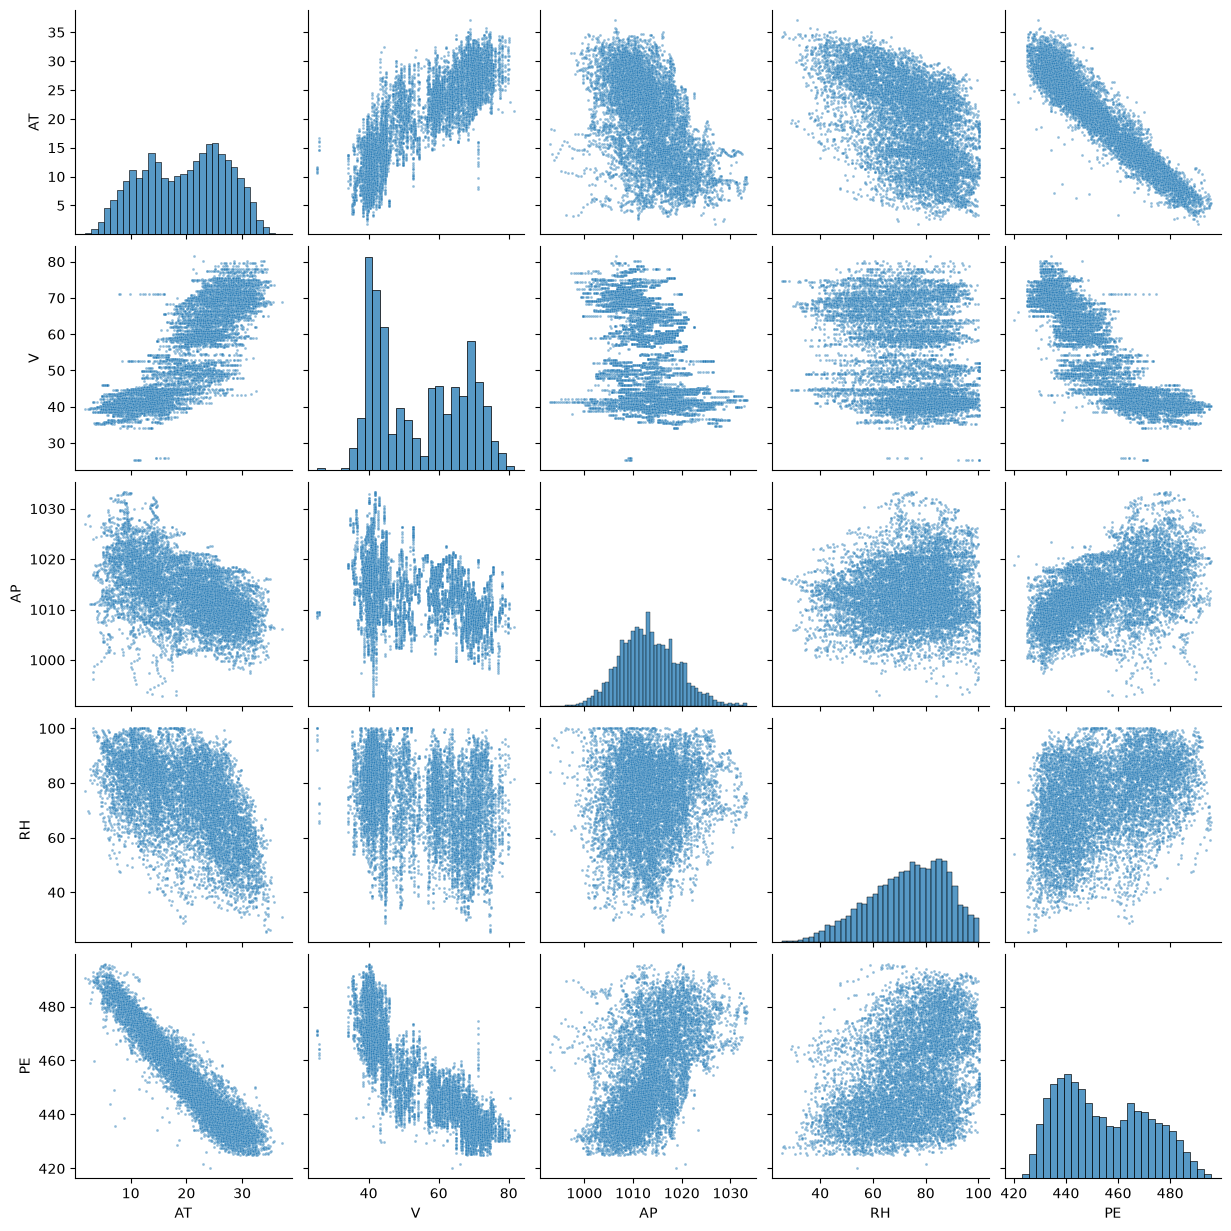

In [ ]:
# Multiple Regression
# x1: ambient temperature
# x2: exhaust vacuum
# x3: ambient pressure
# x4: relative humidity
import polars as pl
import seaborn as sns
import matplotlib.pyplot as plt
import torch
import numpy as np

# a.
URL = 'https://raw.githubusercontent.com/rahulbhadani/Datasets/refs/heads/master/CombinedCyclePowerPlant/Folds5x2_pp.csv'
file = pl.read_csv(URL)
file.columns
file.head()
# sns pairplot provides us with an n x n grid of subplots across the dataset
sns.pairplot(file.to_pandas(), plot_kws={'alpha':0.5, 's':4})
plt.show()

# b.
# multiple linear regression using cauchy loss
# y = w0 + w1x1 + w2x2 + w3x3 + w4x4
class CauchyRegression:
    def __init__(self, c=1.0, learning_rate=0.1, epochs=1000):
        self.c = c
        self.epochs = epochs
        self.learning_rate = learning_rate

        # w0 (intercept) and w = [w1, w2, w3, w4]
        self.w0 = torch.zeros(1, dtype=torch.float64, requires_grad=True)
        self.w = torch.zeros(4, dtype=torch.float64, requires_grad=True)

        # sgd, from linearregression model we did in hw3
        self.optimization = torch.optim.SGD([self.w0, self.w], lr=self.learning_rate)

        self.loss_past = []

    def forward(self, x):
        """linear model: y_hat = w0 + w1*x1 + w2*x2 + w3*x3 + w4*x4"""
        return self.w0 + x @ self.w

    def cauchy_loss(self, y_pred, y_true):
        """avg cauchy loss: (c^2/2) * log(1 + ((y - y_hat)/c)^2)"""
        r = (y_true - y_pred) / self.c
        return torch.mean((self.c ** 2 / 2) * torch.log(1 + r ** 2))
    def fit(self, x_train, y_train):
        x = torch.tensor(np.array(x_train), dtype=torch.float64)
        y = torch.tensor(np.array(y_train), dtype=torch.float64).flatten()
        # used for confidence interval calculation
        self.X_train = np.array(x_train)
        self.y_train = np.array(y_train).flatten()
        
        # standardize the features 
        self.x_mean = x.mean(dim=0)
        self.x_std = x.std(dim=0)
        x_scaled = (x - self.x_mean) / self.x_std

        # start every fit from the same place: w = 0, w0 = mean of y
        with torch.no_grad():
            self.w0.fill_(y.mean().item())
            self.w.zero_()
        self.loss_past = []

        for i in range(self.epochs):
            self.optimization.zero_grad()
            y_pred = self.forward(x_scaled)
            loss_value = self.cauchy_loss(y_pred, y)
            self.loss_past.append(loss_value.item())
            loss_value.backward()
            self.optimization.step()

        # convert the weights back to the original feature units
        with torch.no_grad():
            self.w_orig = self.w / self.x_std
            self.w0_orig = self.w0 - torch.sum(self.w * self.x_mean / self.x_std)
        # c,d
        print("w0 (intercept):", round(self.w0_orig.item(), 6))
        for j, wj in enumerate(self.w_orig):
            print(f"w{j+1}:", round(wj.item(), 6))
        print("final loss:", round(self.loss_past[-1], 6))

    def predict(self, x_new):
        x_new = torch.tensor(np.array(x_new), dtype=torch.float64)
        with torch.no_grad():
            return (self.w0_orig + x_new @ self.w_orig).numpy()
    def conf_int(self, alpha=0.05):
        from scipy import stats

        theta = np.concatenate([[self.w0_orig.item()], self.w_orig.numpy()]) # [w0, w1..w4]
        Z = np.column_stack([np.ones(len(self.X_train)), self.X_train])
        r = (self.y_train - Z @ theta) / self.c

        score = (-self.c * r / (1 + r ** 2))[:, None] * Z # per-sample gradient of the loss
        B = score.T @ score
        h = (1 - r ** 2) / (1 + r ** 2) ** 2 # second derivative per sample
        H = (Z * h[:, None]).T @ Z

        Hinv = np.linalg.inv(H)
        se = np.sqrt(np.diag(Hinv @ B @ Hinv))
        z = stats.norm.ppf(1 - alpha / 2) # 1.96 for 95%

        names = ['w0 (intercept)', 'w1 (AT)', 'w2 (V)', 'w3 (AP)', 'w4 (RH)']
        for n, t, s in zip(names, theta, se):
            print(f"{n:15s} {t: .4f}   95% CI = [{t - z*s: .4f}, {t + z*s: .4f}]")
    def residual_plot(self):
        residuals = self.predict(self.X_train) - self.y_train     # y_hat - y
        names = ['x1 (AT)', 'x2 (V)', 'x3 (AP)', 'x4 (RH)']
        fig, axes = plt.subplots(2, 2, figsize=(12, 8))

        for j, ax in enumerate(axes.ravel()):
            ax.scatter(self.X_train[:, j], residuals, s=4, alpha=0.4)
            ax.axhline(y=0, color='red', linestyle='--')
            ax.set(xlabel=names[j], ylabel=r'y_hat - y')
            ax.grid(True, linestyle='--', alpha=0.6)
        
        plt.tight_layout()
        plt.show()

w0 (intercept): 511.553524
w1: -2.082544
w2: -0.235836
w3: 0.007408
w4: -0.15487
final loss: 1.134774
w0 (intercept)   511.5535   95% CI = [ 468.2809,  554.8261]
w1 (AT)         -2.0825   95% CI = [-2.1434, -2.0217]
w2 (V)          -0.2358   95% CI = [-0.2632, -0.2084]
w3 (AP)          0.0074   95% CI = [-0.0348,  0.0496]
w4 (RH)         -0.1549   95% CI = [-0.1717, -0.1380]


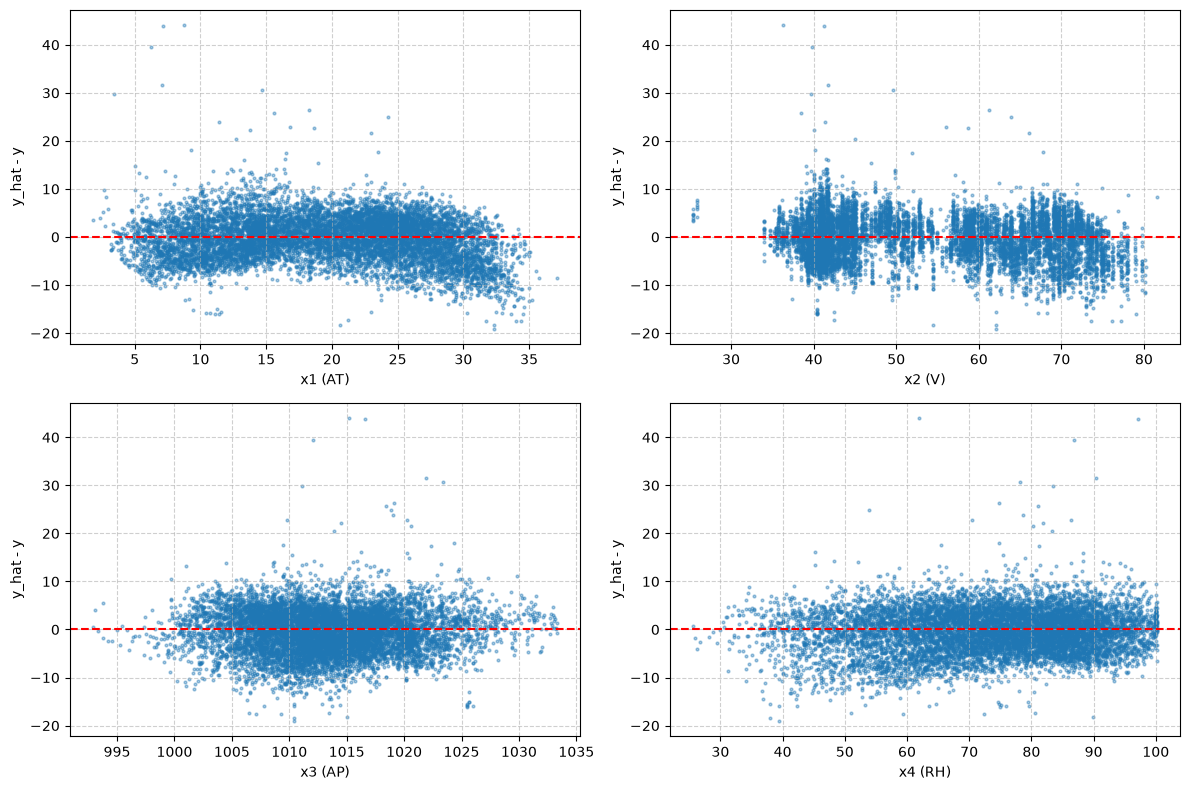

In [ ]:
# for Q5 part b.
X = file.select(['AT', 'V', 'AP', 'RH']).to_numpy()
y = file['PE'].to_numpy()

model = CauchyRegression(c=1.0, learning_rate=0.5, epochs=7000) # loss curve has flattened at this point (in my testing at epochs=5000 it gave the same result)
model.fit(X, y)
# c.
# from this we get the coefficients of the fitted model
# interpreted as ...
# y^ = 511.5535 -2.0825(x1) -0.2358(x2) + 0.0074(x3) - 0.1549(x4)
# where x1 = AT, x2 = V, x3 = AP, x4 = RH

# d.
# we print our final loss from the Cauchy Class aswell
# final loss: 1.134774

# e. what does 95% confidence interval tell us?
model.conf_int()
# the values tell us:
# AT,V, and RH contribute significantly to predicting PE as they do not contain
# 0 in their interval, PE decreases as they increase.
# AP contains zero so we can not definitively say that it contributes significantly
# the other intervals are also very small, which indicates that they are precise

# f.
model.residual_plot() 
# we conclude: 
# the residuals for each of the features show no strong pattern.
# they are centered around zero with roughly constant spread
# a few points have large positive residuals (up to ~44 MW); the Cauchy loss grows
# only logarithmically for large errors, so these outliers have limited influence on the fit
# it could be argued that AT shows a slight nonlinear trend, but its not strong enough for me to guarantee nonlinearity.


In [ ]:
# Multiple Regression bonus
import numpy as np
import statsmodels.api as sm
from statsmodels.base.model import GenericLikelihoodModel

class CauchyModel(GenericLikelihoodModel):
    # endog = target variable 'y' (PE)
    # exog = feature matrix
    def __init__(self, endog, exog, c=1.0, **kwds):
        super().__init__(endog,exog, **kwds) # parent stores exog/endog
        self.c = c # Cauchy loss
    def nloglikeobs(self, params):
        # params = [w0,w1,w2,w3,w4]
        y_hat = self.exog @ params # predictor
        r = (self.endog - y_hat) / self.c # scaling of result
        return (self.c ** 2 / 2) * np.log(1 + r ** 2) # loss 
    

In [43]:
# add 1's column so w0 can be calculated
exog = sm.add_constant(X)
start = sm.OLS(y, exog).fit().params # optimizer starting point
# disp = 0 hides iteration log, 'bfgs' refers to gradient optimizer
results = CauchyModel(y, exog, c=1.0).fit(start_params=start, method='bfgs', maxiter = 10000, disp=0)

print(results.summary(xname=['w0 (intercept)', 'w1 (AT)', 'w2 (V)', 'w3 (AP)', 'w4 (RH)']))

                             CauchyModel Results                              
Dep. Variable:                      y   Log-Likelihood:                -10858.
Model:                    CauchyModel   AIC:                         2.173e+04
Method:            Maximum Likelihood   BIC:                         2.176e+04
Date:                Thu, 29 Oct 2026                                         
Time:                        01:46:00                                         
No. Observations:                9568                                         
Df Residuals:                    9563                                         
Df Model:                           4                                         
                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------
w0 (intercept)   511.5589     11.693     43.750      0.000     488.641     534.477
w1 (AT)           -2.0826      0.018   -

# the statsmodels coefficients match the pytorch class (511.56, -2.0826, -0.2358, 0.0074, -0.1549)
# final loss = -log-likelihood / n = 10858 / 9568 = 1.1348, same as the pytorch loss
# the confidence intervals are a bit narrower than the sandwich ones from CauchyRegression,
# because statsmodels treats the loss as a true likelihood, but both say AT, V, RH are significant while AP is not.

w0 (intercept): 511.553524
w1: -2.082544
w2: -0.235836
w3: 0.007408
w4: -0.15487
final loss: 1.134774
w0 (intercept): 511.5535
w1: -2.0825
w2: -0.2358
w3: 0.0074
w4: -0.1549
Final loss: 1.1347737267979034
w0 (intercept)   511.5535   95% CI = [ 468.2809,  554.8261]
w1 (AT)         -2.0825   95% CI = [-2.1434, -2.0217]
w2 (V)          -0.2358   95% CI = [-0.2632, -0.2084]
w3 (AP)          0.0074   95% CI = [-0.0348,  0.0496]
w4 (RH)         -0.1549   95% CI = [-0.1717, -0.1380]


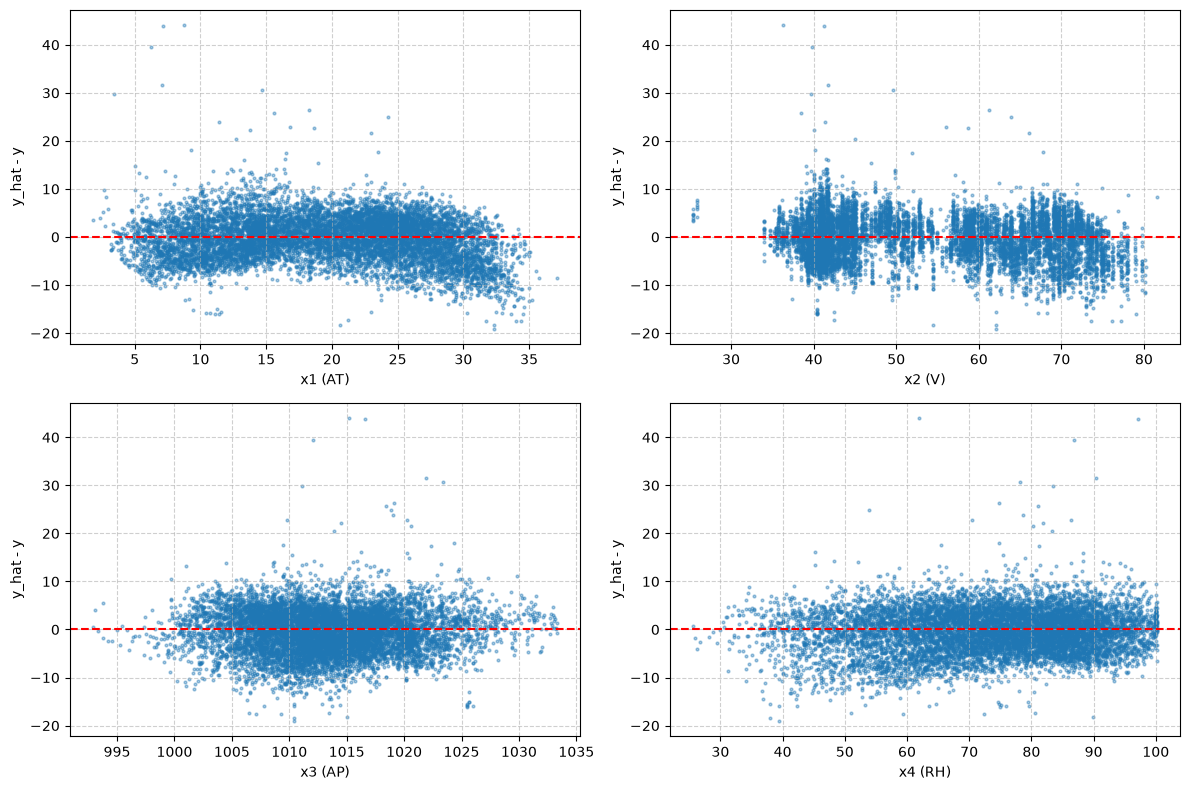

In [23]:
# importing & use of Cauchy Regression model
from prettyjoey.model.regression import CauchyRegression as PackageCauchyRegression
# load the data
X = file.select(['AT', 'V', 'AP', 'RH']).to_numpy()
y = file['PE'].to_numpy()

model_pkg = PackageCauchyRegression(c=1.0, learning_rate=0.5, epochs=7000)
model_pkg.fit(X, y)

model_pkg.coefficients()
print("Final loss:", model_pkg.final_loss())
model_pkg.conf_int()
model_pkg.residual_plot()

In [ ]:
# Logistics Regression on a real world dataset

import polars as pl
from sklearn.model_selection import train_test_split
import numpy as np 
import torch
# load only the columns being used (the file has 90 total columns)
PATH = "listings.csv"
feature_cols = [
    "accommodates", # number of guests allowed
    "minimum_nights", # minimum length of stay
    "availability_365", # days available in the next year
    "number_of_reviews", # total reviews received
    "reviews_per_month", # average reviews per month
    "review_scores_rating", # average review rating (1 to 5)
    "calculated_host_listings_count", # number of listings the host has
]
raw = pl.read_csv(PATH, columns=feature_cols + ["host_is_superhost"])
print(raw.shape)
raw.head()

# build label

# b. build the label (1 = superhost, 0 = not) and drop rows with missing values
df = (
    raw.filter(pl.col("host_is_superhost").is_in(["t", "f"])).with_columns((pl.col("host_is_superhost") == "t").cast(pl.Int64).alias("is_superhost"))
    .drop("host_is_superhost")
    .drop_nulls() # some listings have no ratings so we can drop these and be fine to do so
)
print(df.shape)
df.head()

# c. check for class imbalance
print(df["is_superhost"].value_counts().sort("is_superhost"))
# this tell sus that 17.8% of the listings are superhost and the remaining percent is not

print("fraction superhost:", round(df["is_superhost"].mean(), 4))

X = df.drop("is_superhost").to_numpy().astype(np.float64)
y = df["is_superhost"].to_numpy().astype(np.float64)

# stratify=y keeps the superhost fraction the same in train and test (17.8% to 82.2%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=1/3, random_state=0, stratify=y
)

# standardize using the TRAINING mean and std only, then apply them to the test set
mean, std = X_train.mean(axis=0), X_train.std(axis=0)
X_train_s = (X_train - mean) / std
X_test_s = (X_test - mean) / std

print(X_train.shape, X_test.shape)
print("superhost fraction, train:", round(y_train.mean(), 4), " test:", round(y_test.mean(), 4))


(10612, 8)
(9342, 8)
shape: (2, 2)
┌──────────────┬───────┐
│ is_superhost ┆ count │
│ ---          ┆ ---   │
│ i64          ┆ u32   │
╞══════════════╪═══════╡
│ 0            ┆ 7677  │
│ 1            ┆ 1665  │
└──────────────┴───────┘
fraction superhost: 0.1782
(6228, 7) (3114, 7)
superhost fraction, train: 0.1782  test: 0.1782


In [ ]:
# Logistics Regression Class
import numpy as np
import torch


class LogisticRegression:
    # start with learning rate 0.1
    # will check with loss curve
    # 50 epochs could be enough for loss curve to flatten
    # will also check this later
    # batch side 64 for SGD, many updates per epoch
    # if batch size was = 1 like the lecture 
    def __init__(self, learning_rate=0.1, epochs=50, batch_size=64, seed=0):
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.batch_size = batch_size
        self.seed = seed
        self.loss_past = [] # full-training-set loss after each epoch

    def sigmoid(self, z):
        # from in class
        return 1 / (1 + torch.exp(-z))

    def forward(self, x):
        """h(x) = sigmoid(w0 + x @ w): the predicted probability of class 1"""
        return self.sigmoid(self.w0 + x @ self.w)
    
    # negative log likelyhood model
    # gives simple gradient when combined with sigmoid funct.
    # CLAMP forces log to always be between [0,1]
    def cross_entropy(self, h, y):
        """average cross-entropy; the clamp keeps log() away from 0"""
        h = torch.clamp(h, 1e-12, 1 - 1e-12)
        return -torch.mean(y * torch.log(h) + (1 - y) * torch.log(1 - h))
    
    # autograd requires tensor inputs
    def fit(self, x_train, y_train):
        x = torch.tensor(np.array(x_train), dtype=torch.float64)
        y = torch.tensor(np.array(y_train), dtype=torch.float64).flatten()
        n = x.shape[0]

        # weights and intercept start at zero (because of convex loss)
        self.w = torch.zeros(x.shape[1], dtype=torch.float64, requires_grad=True)
        self.w0 = torch.zeros(1, dtype=torch.float64, requires_grad=True)

        # sgd implementation       
        self.optimization = torch.optim.SGD([self.w0, self.w], lr=self.learning_rate)

        gen = torch.Generator().manual_seed(self.seed)
        self.loss_past = []

        for epoch in range(self.epochs):
            order = torch.randperm(n, generator=gen) # shuffle every epoch
            for start in range(0, n, self.batch_size): # one SGD step per mini-batch
                idx = order[start:start + self.batch_size]
                self.optimization.zero_grad()
                loss = self.cross_entropy(self.forward(x[idx]), y[idx])
                loss.backward()
                self.optimization.step()

            with torch.no_grad():
                # record loss on all training data
                self.loss_past.append(self.cross_entropy(self.forward(x), y).item())

        print("w0 (intercept):", round(self.w0.item(), 6))
        for j, wj in enumerate(self.w):
            print(f"w{j+1}:", round(wj.item(), 6))
        print("final training loss:", round(self.loss_past[-1], 6))

    def predict_proba(self, x_new):
        x_new = torch.tensor(np.array(x_new), dtype=torch.float64)
        with torch.no_grad():
            return self.forward(x_new).numpy()

    def predict(self, x_new, threshold=0.5):
        return (self.predict_proba(x_new) >= threshold).astype(int)

w0 (intercept): -1.577445
w1: -0.011077
w2: 0.051852
w3: 0.238222
w4: 0.632295
w5: 0.516979
w6: 0.261455
w7: 0.207365
final training loss: 0.384553


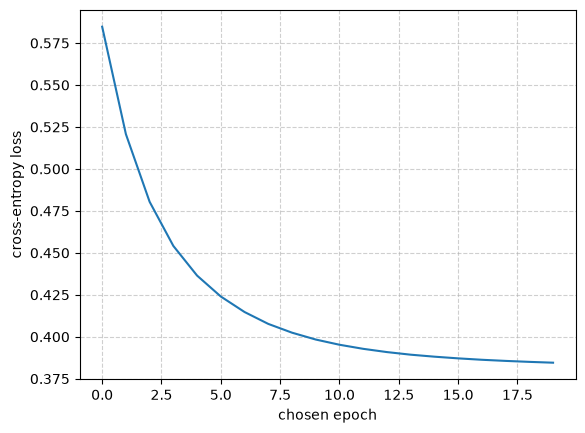

In [15]:
# Logistics Regression test box

import matplotlib.pyplot as plt
# in this case we can test with epochs = 30
# epochs = 30 was an overestimation, curve flattens ~20

clf = LogisticRegression(learning_rate=0.01, epochs=20)

clf.fit(X_train_s, y_train) # standardized inputs: raw values like minimum_nights (up to 800) would make the updates unstable

plt.plot(clf.loss_past)
plt.xlabel("chosen epoch")
plt.ylabel("cross-entropy loss")
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()


# need to check for class imbalance


w0 (intercept): -1.577445
w1: -0.011077
w2: 0.051852
w3: 0.238222
w4: 0.632295
w5: 0.516979
w6: 0.261455
w7: 0.207365
final training loss: 0.384553


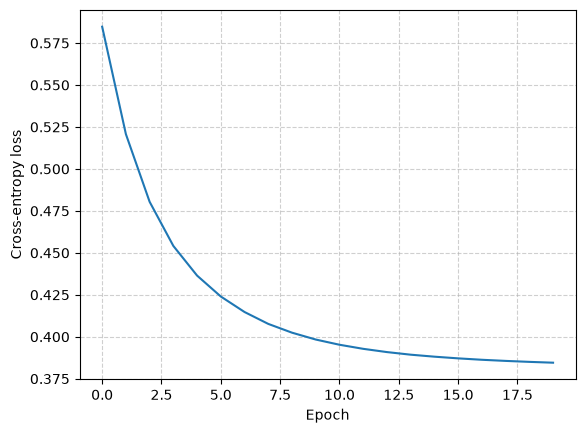

In [ ]:
# logistic regression bonus
# formatted like this to show that its imported from the package and not the cell above
from prettyjoey.model.logit import LogisticRegression as PackageLogisticRegression

clf_pkg = PackageLogisticRegression(learning_rate=0.01, epochs=20, batch_size=64)
clf_pkg.fit(X_train_s, y_train)

plt.plot(clf.loss_past)
plt.xlabel("Epoch"); plt.ylabel("Cross-entropy loss")
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()